In [4]:
#!pip install catboost
#!pip install xgboost
#!pip install lightgbm

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
import os
os.makedirs('results', exist_ok=True)

## Dataset Description

The WeatherAUS dataset contains daily weather observations collected from different locations in Australia. It is used to predict whether it will rain the next day.

### Features Description

| Column Name | Description |
|---|---|
| Date | Date of weather observation |
| Location | Location where the weather was recorded |
| MinTemp | Minimum temperature during the day |
| MaxTemp | Maximum temperature during the day |
| Rainfall | Amount of rainfall recorded |
| Evaporation | Amount of water evaporation |
| Sunshine | Number of hours of sunshine |
| WindGustDir | Direction of the strongest wind gust |
| WindGustSpeed | Speed of the strongest wind gust |
| WindDir9am | Wind direction at 9 AM |
| WindDir3pm | Wind direction at 3 PM |
| WindSpeed9am | Wind speed at 9 AM |
| WindSpeed3pm | Wind speed at 3 PM |
| Humidity9am | Humidity percentage at 9 AM |
| Humidity3pm | Humidity percentage at 3 PM |
| Pressure9am | Atmospheric pressure at 9 AM |
| Pressure3pm | Atmospheric pressure at 3 PM |
| Cloud9am | Cloud coverage at 9 AM |
| Cloud3pm | Cloud coverage at 3 PM |
| Temp9am | Temperature at 9 AM |
| Temp3pm | Temperature at 3 PM |
| RainToday | Indicates whether it rained today (Yes/No) |
| RISK_MM | Rainfall amount recorded for the next day |
| RainTomorrow | Indicates whether it will rain tomorrow (Target Variable) |

### Target Variable

**RainTomorrow** is the target column used for binary classification. It has two possible values: Yes and No.

In [6]:
df= pd.read_csv('../dataset/weatherAUS(Target column RainTomorrow).csv')

In [7]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,0.0,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,0.0,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,0.0,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,1.0,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,0.2,No


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142193 entries, 0 to 142192
Data columns (total 24 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           142193 non-null  object 
 1   Location       142193 non-null  object 
 2   MinTemp        141556 non-null  float64
 3   MaxTemp        141871 non-null  float64
 4   Rainfall       140787 non-null  float64
 5   Evaporation    81350 non-null   float64
 6   Sunshine       74377 non-null   float64
 7   WindGustDir    132863 non-null  object 
 8   WindGustSpeed  132923 non-null  float64
 9   WindDir9am     132180 non-null  object 
 10  WindDir3pm     138415 non-null  object 
 11  WindSpeed9am   140845 non-null  float64
 12  WindSpeed3pm   139563 non-null  float64
 13  Humidity9am    140419 non-null  float64
 14  Humidity3pm    138583 non-null  float64
 15  Pressure9am    128179 non-null  float64
 16  Pressure3pm    128212 non-null  float64
 17  Cloud9am       88536 non-null

In [9]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RISK_MM
count,141556.000000,141871.000000,140787.000000,81350.000000,74377.000000,132923.000000,140845.000000,139563.000000,140419.000000,138583.000000,128179.000000,128212.000000,88536.000000,85099.000000,141289.000000,139467.000000,142193.000000
mean,12.186400,23.226784,2.349974,5.469824,7.624853,39.984292,14.001988,18.637576,68.843810,51.482606,1017.653758,1015.258204,4.437189,4.503167,16.987509,21.687235,2.360682
std,6.403283,7.117618,8.465173,4.188537,3.781525,13.588801,8.893337,8.803345,19.051293,20.797772,7.105476,7.036677,2.887016,2.720633,6.492838,6.937594,8.477969
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,977.100000,0.000000,0.000000,-7.200000,-5.400000,0.000000
25%,7.600000,17.900000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000,0.000000
50%,12.000000,22.600000,0.000000,4.800000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000,0.000000
75%,16.800000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000,0.800000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.700000,371.000000


In [10]:
df.shape

(142193, 24)

In [11]:
df.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RISK_MM', 'RainTomorrow'],
      dtype='object')

In [12]:
df.isnull().sum()

Date                 0
Location             0
MinTemp            637
MaxTemp            322
Rainfall          1406
Evaporation      60843
Sunshine         67816
WindGustDir       9330
WindGustSpeed     9270
WindDir9am       10013
WindDir3pm        3778
WindSpeed9am      1348
WindSpeed3pm      2630
Humidity9am       1774
Humidity3pm       3610
Pressure9am      14014
Pressure3pm      13981
Cloud9am         53657
Cloud3pm         57094
Temp9am            904
Temp3pm           2726
RainToday         1406
RISK_MM              0
RainTomorrow         0
dtype: int64

In [13]:
# Proof that RISK_MM leaks the target
print(df.groupby('RainTomorrow')['RISK_MM'].describe())

                 count       mean        std  min  25%  50%   75%    max
RainTomorrow                                                            
No            110316.0   0.075254   0.199154  0.0  0.0  0.0   0.0    1.0
Yes            31877.0  10.269809  15.487202  1.1  2.4  5.2  11.8  371.0


In [14]:
#Data Leakage
df = df.drop(columns=['RISK_MM'])
df = df.dropna(subset=['RainTomorrow'])

In [15]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df = df.drop(columns=['Date'])

In [54]:
df.duplicated().sum()

np.int64(0)

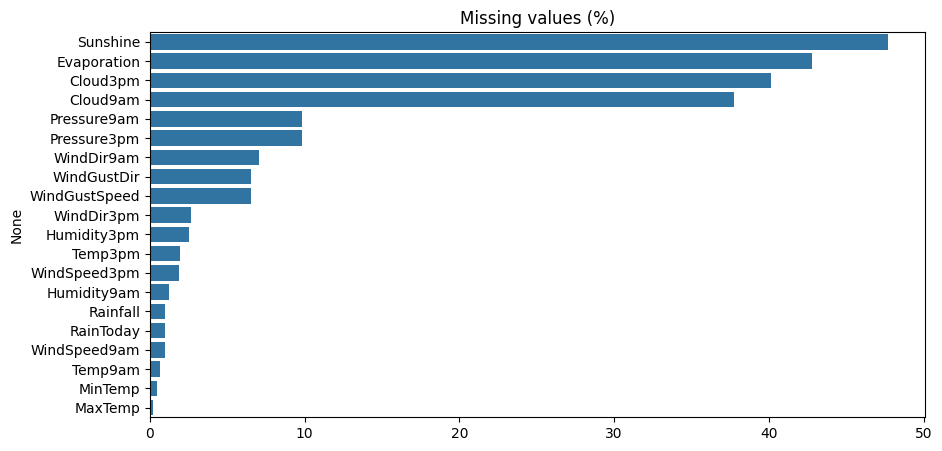

In [16]:
missing = df.isnull().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing.values, y=missing.index)
plt.title('Missing values (%)')
plt.show()

Evaporation, Sunshine and the two Cloud columns have the most missing values (40-48%).
I did not drop them. I filled them inside the pipeline instead, so no information is lost.

# **EDA**

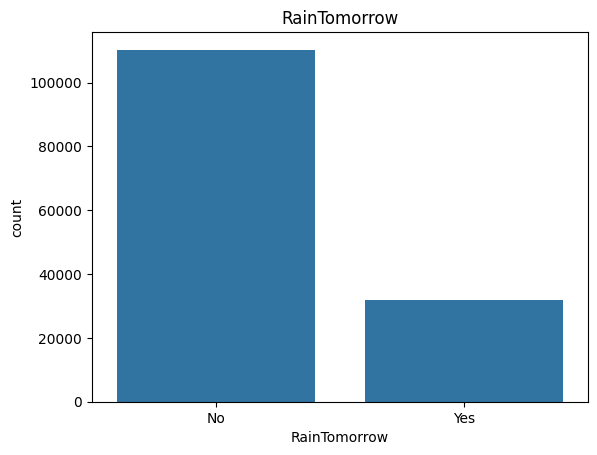

RainTomorrow
No     0.775819
Yes    0.224181
Name: proportion, dtype: float64


In [17]:
sns.countplot(x='RainTomorrow', data=df)
plt.title('RainTomorrow')
plt.show()

print(df['RainTomorrow'].value_counts(normalize=True))

 The data is imbalanced (about 78% No and 22% Yes), so accuracy alone is not enough. We also use precision, recall, F1 and ROC-AUC.

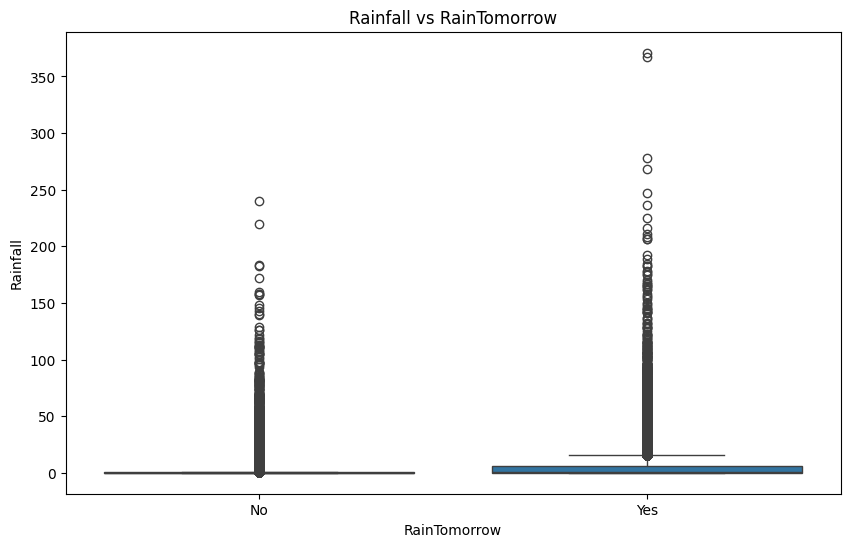

In [18]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='RainTomorrow', y='Rainfall', data=df)
plt.title('Rainfall vs RainTomorrow')
plt.show()

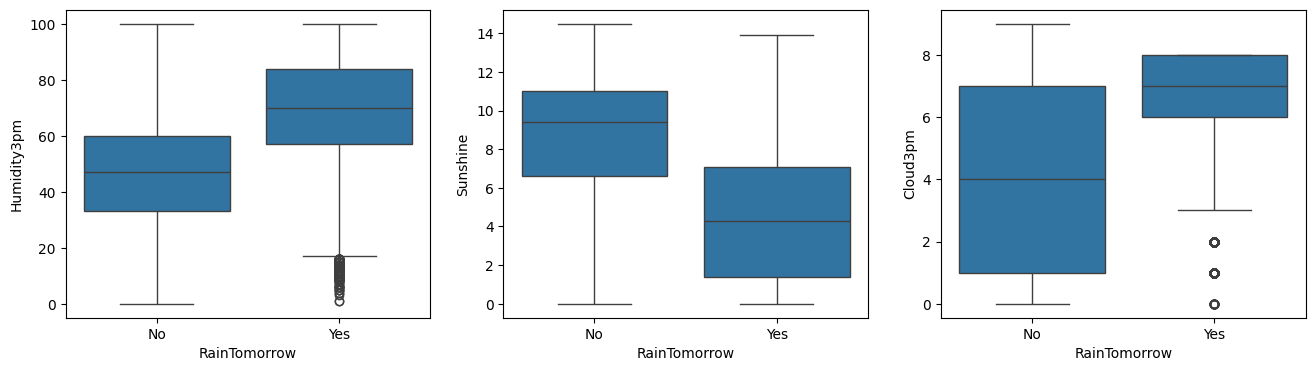

In [56]:
# Important features vs target
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Humidity3pm', 'Sunshine', 'Cloud3pm']):
    sns.boxplot(x='RainTomorrow', y=col, data=df, ax=ax)
plt.show()

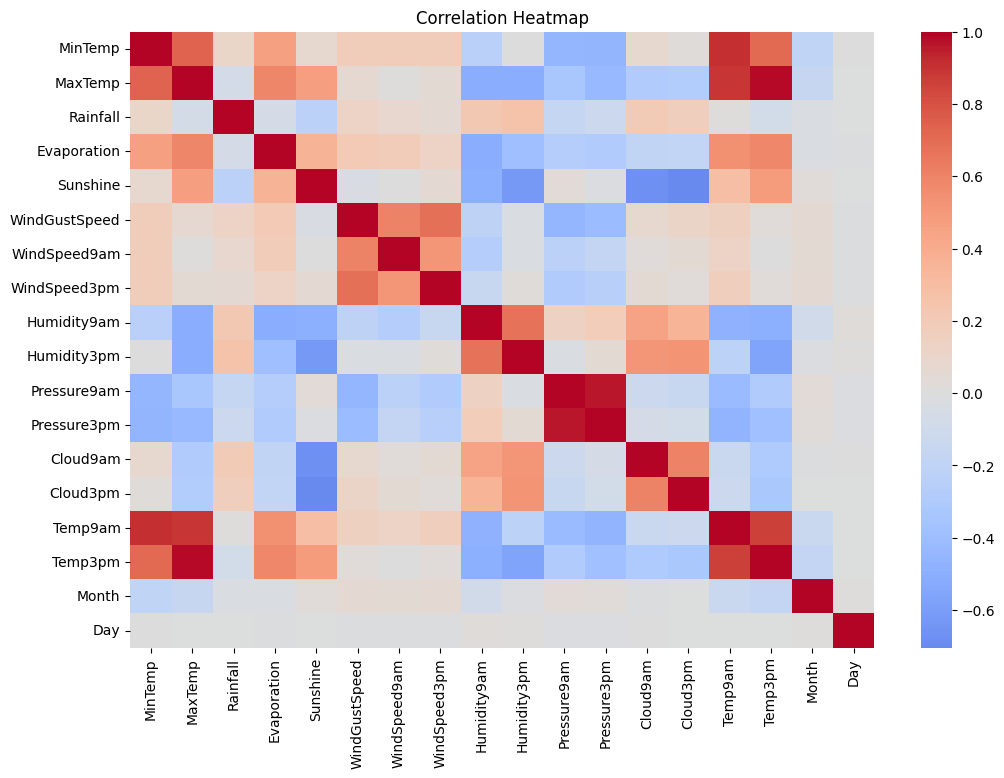

In [55]:
# Correlation
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

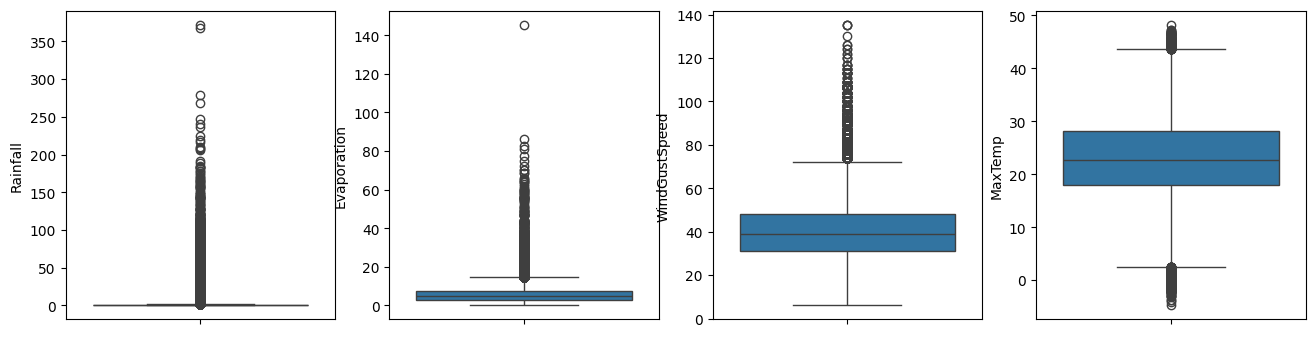

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['Rainfall', 'Evaporation', 'WindGustSpeed', 'MaxTemp']):
    sns.boxplot(y=df[col], ax=ax)
plt.show()

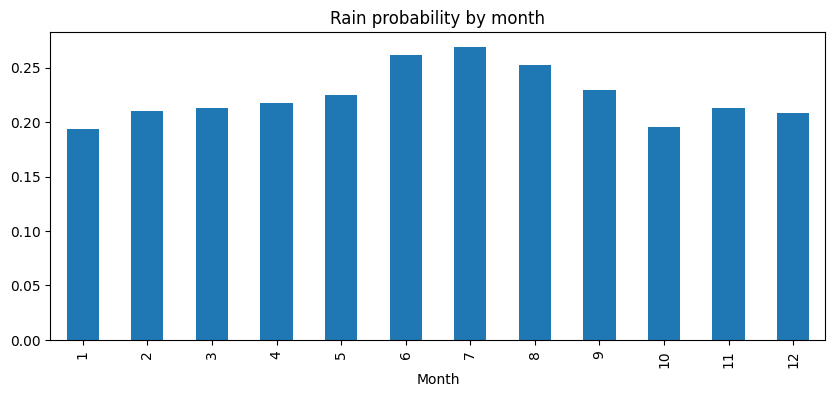

In [57]:
# Rain rate by month
(df['RainTomorrow'].eq('Yes').groupby(df['Month']).mean()
   .plot(kind='bar', figsize=(10, 4), title='Rain probability by month'))
plt.show()

Rainfall and Evaporation have extreme values (Rainfall max is 371 mm).
These look like real heavy-rain days, not errors, so I kept them.
Tree-based models are not sensitive to outliers anyway.

In [20]:
X = df.drop(columns=['RainTomorrow'])
y = df['RainTomorrow']

In [21]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

In [22]:
le_target = LabelEncoder()
y = le_target.fit_transform(y)

## **Train Test Split**

RISK_MM was removed because it contains the next day's rainfall, which would leak the answer.
The Date column was split into Month and Day. This is the only feature engineering I did.
The split is 80/20 and stratified, because the classes are imbalanced.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

## **Preprocessing**

In [24]:

num_cols = X_train.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

In [25]:

# Preprocessing Pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])



In [26]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
)

In [28]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN Classifier": KNeighborsClassifier(n_neighbors=5),
    "SVM (LinearSVC)": CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10), n_estimators=50, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='logloss', n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1, n_jobs=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, random_state=42, verbose=0)
}

results = []

In [29]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay
)

100%|██████████| 14/14 [04:39<00:00, 19.97s/it]


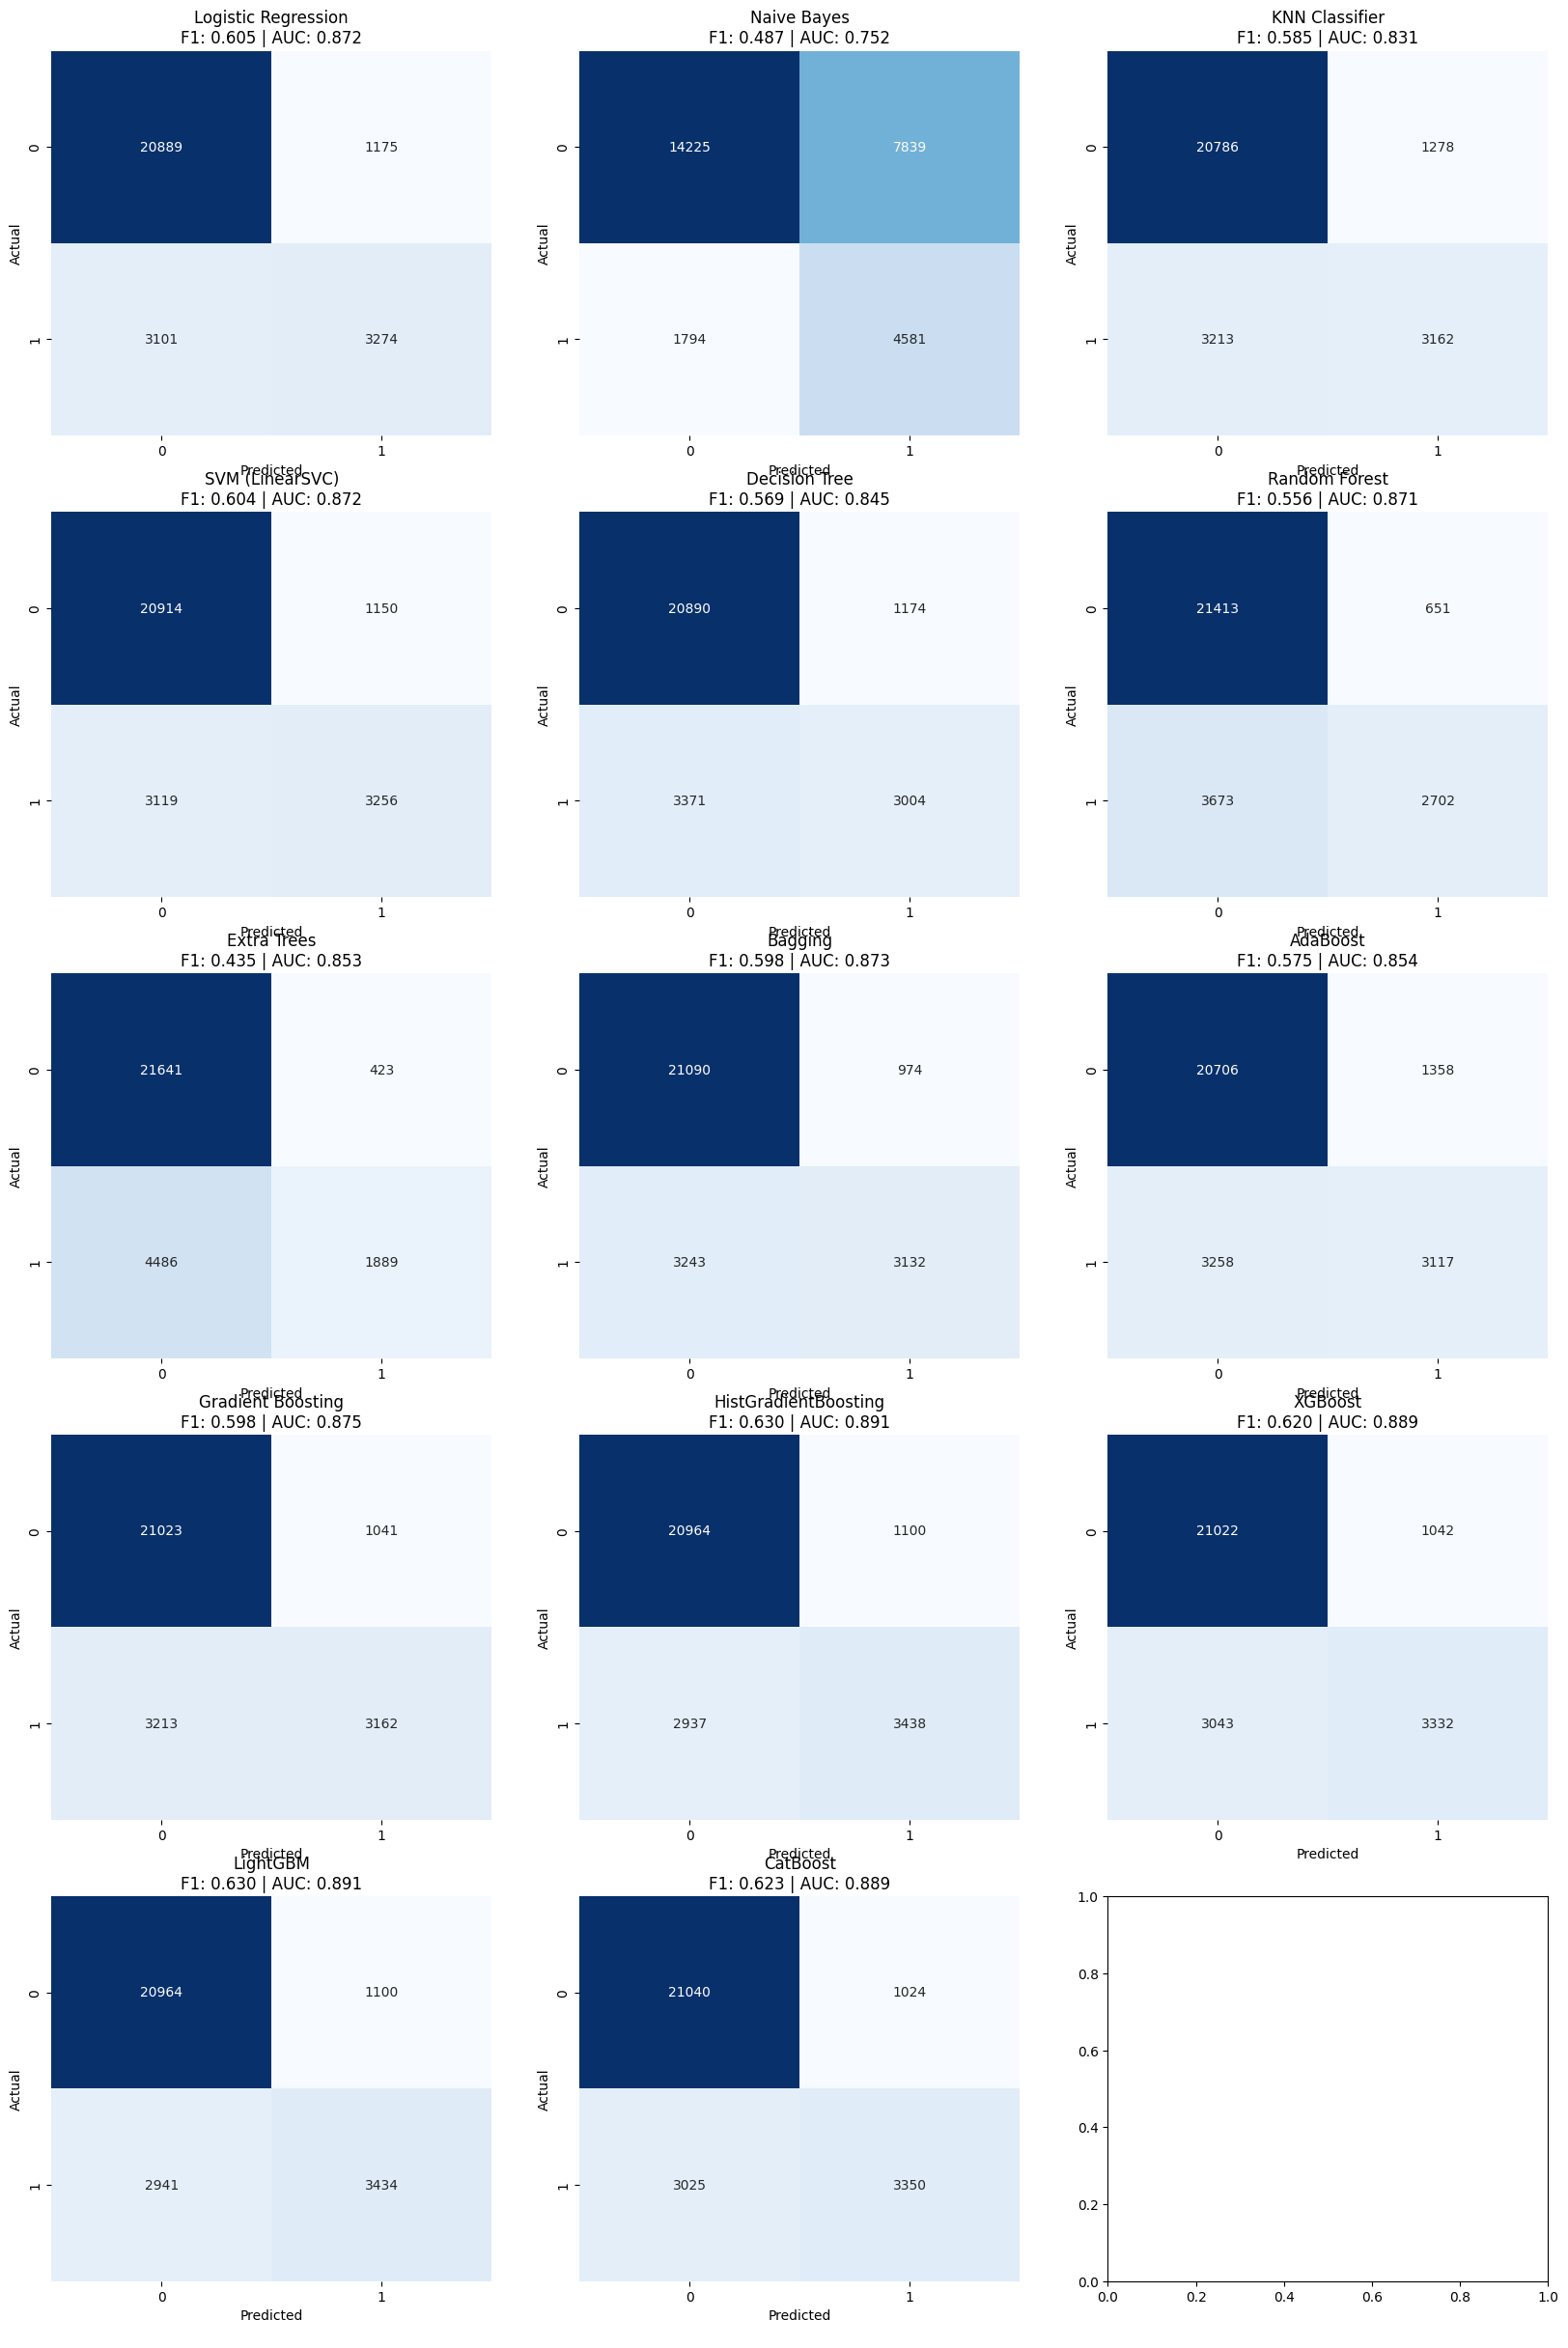

In [30]:
fig, axes = plt.subplots(5, 3, figsize=(20, 30))
axes = axes.flatten()

for idx, (name, model) in enumerate(tqdm(models.items())):
    model.fit(X_train_processed, y_train)

    y_train_pred = model.predict(X_train_processed)
    y_test_pred = model.predict(X_test_processed)
    y_test_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": round(accuracy_score(y_train, y_train_pred), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
        "Precision": round(precision_score(y_test, y_test_pred), 4),
        "Recall": round(recall_score(y_test, y_test_pred), 4),
        "F1-Score": round(f1_score(y_test, y_test_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_test_prob), 4)
    })
    # Confusion Matrix
    plt.subplot(5, 3, idx + 1)
    cm = confusion_matrix(y_test, y_test_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name }\nF1: {f1_score(y_test, y_test_pred):.3f} | AUC: {roc_auc_score(y_test, y_test_prob):.3f}")
    axes[idx].set_xlabel("Predicted\n")
    axes[idx].set_ylabel("Actual")

In [31]:
import sklearn
import lightgbm
import joblib

print("Scikit-learn:", sklearn.__version__)
print("LightGBM:", lightgbm.__version__)
print("Joblib:", joblib.__version__)

Scikit-learn: 1.7.2
LightGBM: 4.7.0
Joblib: 1.5.3


I trained all the models from the course on the same preprocessed data.
SVM is LinearSVC (with calibration) because the normal SVC is too slow on 140k rows.
Models were compared by F1 and ROC-AUC, not accuracy, because the data is imbalanced.

In [32]:
comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
print(comparison_df.to_string(index=False))

               Model  Train Accuracy  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC
HistGradientBoosting          0.8654         0.8580     0.7576  0.5393    0.6301   0.8912
            LightGBM          0.8660         0.8579     0.7574  0.5387    0.6296   0.8910
            CatBoost          0.8636         0.8576     0.7659  0.5255    0.6233   0.8888
             XGBoost          0.8672         0.8564     0.7618  0.5227    0.6200   0.8893
 Logistic Regression          0.8479         0.8496     0.7359  0.5136    0.6050   0.8720
     SVM (LinearSVC)          0.8477         0.8499     0.7390  0.5107    0.6040   0.8717
   Gradient Boosting          0.8518         0.8504     0.7523  0.4960    0.5978   0.8754
             Bagging          0.8735         0.8517     0.7628  0.4913    0.5977   0.8732
      KNN Classifier          0.8828         0.8421     0.7122  0.4960    0.5847   0.8310
            AdaBoost          0.8365         0.8377     0.6965  0.4889    0.5746   0.8537
       Dec

In [33]:
before = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    before[name] = cross_val_score(pipe, X_train, y_train, cv=3, scoring='f1').mean()
    print(name, round(before[name], 4))

Logistic Regression 0.5994
Naive Bayes 0.4816
KNN Classifier 0.5679
SVM (LinearSVC) 0.5984
Decision Tree 0.5693
Random Forest 0.5486
Extra Trees 0.4332
Bagging 0.5925
AdaBoost 0.573
Gradient Boosting 0.5966
HistGradientBoosting 0.6258
XGBoost 0.6216
LightGBM 0.627
CatBoost 0.6234


In [34]:
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay
)

## **GridSearchCV**

GridSearchCV used 3-fold CV on the training set only. The test set was not touched.
LightGBM gave the best F1 (0.6446), followed by XGBoost and HistGradientBoosting.
Boosting models are the best here. Naive Bayes is the weakest because it assumes features are independent.
Extra Trees has high precision but very low recall, so it misses most rainy days.

In [35]:
from sklearn.model_selection import GridSearchCV

In [36]:
param_grids = {
    "Logistic Regression": {'model__C': [0.1, 1, 10]},
    "Naive Bayes": {'model__var_smoothing': [1e-9, 1e-8, 1e-7]},
    "KNN Classifier": {'model__n_neighbors': [7, 15]},
    "SVM (LinearSVC)": {'model__estimator__C': [0.1, 1]},
    "Decision Tree": {'model__max_depth': [5, 8, 12],'model__min_samples_leaf': [10, 50]},
    "Random Forest": {'model__n_estimators': [100, 200],'model__max_depth': [10, 16]},
    "Bagging": {'model__n_estimators': [10, 50, 100]},
    "Extra Trees": {'model__n_estimators': [100, 200],'model__max_depth': [10, 16]},
    "AdaBoost": {'model__n_estimators': [50, 150],'model__learning_rate': [0.5, 1.0]},
    "Gradient Boosting": {'model__n_estimators': [100, 150],'model__max_depth': [3, 4]},
    "HistGradientBoosting": {'model__learning_rate': [0.05, 0.1],'model__max_leaf_nodes': [31, 63]},
    "XGBoost": {'model__n_estimators': [200, 300],'model__max_depth': [4, 6]},
    "LightGBM": {'model__n_estimators': [200, 400],'model__learning_rate': [0.05, 0.1],'model__num_leaves': [31, 63]},
    "CatBoost": {'model__depth': [4, 6],'model__learning_rate': [0.05, 0.1]}
}



In [37]:
best_models = {}
grid_results = []
grid_errors = {}

In [38]:


for name, model in models.items():

    if name not in param_grids:
        print(f"Skipping {name}: No parameter grid found.")
        continue

    print(f"\nTuning {name}...")

    try:
        pipeline = Pipeline([
            ('prep', preprocessor),
            ('model', model)
        ])

        grid = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[name],
            scoring='f1',
            cv=3,
            n_jobs=-1,
            refit=True
        )

        grid.fit(X_train, y_train)

        best_models[name] = grid.best_estimator_

        grid_results.append({
            'Model': name,
            'Best CV F1': grid.best_score_,
            'Best Parameters': grid.best_params_
        })

        print("Best F1:", round(grid.best_score_, 4))
        print("Best Parameters:", grid.best_params_)

    except Exception as e:
        grid_errors[name] = str(e)
        print(f"Error in {name}: {e}")


grid_comparison = pd.DataFrame(grid_results)

grid_comparison = grid_comparison.sort_values(
    by='Best CV F1',
    ascending=False
).reset_index(drop=True)

display(grid_comparison)

print("\nNumber of successful models:", len(best_models))
print("Number of failed models:", len(grid_errors))



Tuning Logistic Regression...
Best F1: 0.5994
Best Parameters: {'model__C': 1}

Tuning Naive Bayes...
Best F1: 0.4816
Best Parameters: {'model__var_smoothing': 1e-07}

Tuning KNN Classifier...
Best F1: 0.5682
Best Parameters: {'model__n_neighbors': 7}

Tuning SVM (LinearSVC)...
Best F1: 0.5985
Best Parameters: {'model__estimator__C': 0.1}

Tuning Decision Tree...
Best F1: 0.5771
Best Parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 50}

Tuning Random Forest...
Best F1: 0.5814
Best Parameters: {'model__max_depth': 16, 'model__n_estimators': 200}

Tuning Extra Trees...
Best F1: 0.4939
Best Parameters: {'model__max_depth': 16, 'model__n_estimators': 100}

Tuning Bagging...
Best F1: 0.593
Best Parameters: {'model__n_estimators': 100}

Tuning AdaBoost...
Best F1: 0.5801
Best Parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 150}

Tuning Gradient Boosting...
Best F1: 0.6141
Best Parameters: {'model__max_depth': 4, 'model__n_estimators': 150}

Tuning HistGradien

,Model,Best CV F1,Best Parameters
0,LightGBM,0.644560,"{'model__learning_rate': 0.1, 'model__n_estima..."
1,XGBoost,0.640633,"{'model__max_depth': 6, 'model__n_estimators':..."
2,HistGradientBoosting,0.634559,"{'model__learning_rate': 0.1, 'model__max_leaf..."
3,CatBoost,0.623414,"{'model__depth': 6, 'model__learning_rate': 0.1}"
4,Gradient Boosting,0.614091,"{'model__max_depth': 4, 'model__n_estimators':..."
5,Logistic Regression,0.599352,{'model__C': 1}
6,SVM (LinearSVC),0.598489,{'model__estimator__C': 0.1}
7,Bagging,0.593042,{'model__n_estimators': 100}
8,Random Forest,0.581376,"{'model__max_depth': 16, 'model__n_estimators'..."
9,AdaBoost,0.580089,"{'model__learning_rate': 1.0, 'model__n_estima..."



Number of successful models: 14
Number of failed models: 0


In [39]:
rows = []

for _, row in grid_comparison.iterrows():
    model_name = row['Model']

    if model_name in before:
        rows.append({
            'Model': model_name,
            'F1 before': before[model_name],
            'F1 after': row['Best CV F1'],
            'Best Params': row['Best Parameters']
        })

comparison = pd.DataFrame(rows)

comparison = comparison.sort_values(
    'F1 after',
    ascending=False
).reset_index(drop=True)

comparison['F1 before'] = comparison['F1 before'].round(4)
comparison['F1 after'] = comparison['F1 after'].round(4)

comparison.to_csv('../results/comparison_before_after.csv', index=False)

display(comparison)

,Model,F1 before,F1 after,Best Params
0,LightGBM,0.6270,0.6446,"{'model__learning_rate': 0.1, 'model__n_estima..."
1,XGBoost,0.6216,0.6406,"{'model__max_depth': 6, 'model__n_estimators':..."
2,HistGradientBoosting,0.6258,0.6346,"{'model__learning_rate': 0.1, 'model__max_leaf..."
3,CatBoost,0.6234,0.6234,"{'model__depth': 6, 'model__learning_rate': 0.1}"
4,Gradient Boosting,0.5966,0.6141,"{'model__max_depth': 4, 'model__n_estimators':..."
5,Logistic Regression,0.5994,0.5994,{'model__C': 1}
6,SVM (LinearSVC),0.5984,0.5985,{'model__estimator__C': 0.1}
7,Bagging,0.5925,0.5930,{'model__n_estimators': 100}
8,Random Forest,0.5486,0.5814,"{'model__max_depth': 16, 'model__n_estimators'..."
9,AdaBoost,0.5730,0.5801,"{'model__learning_rate': 1.0, 'model__n_estima..."


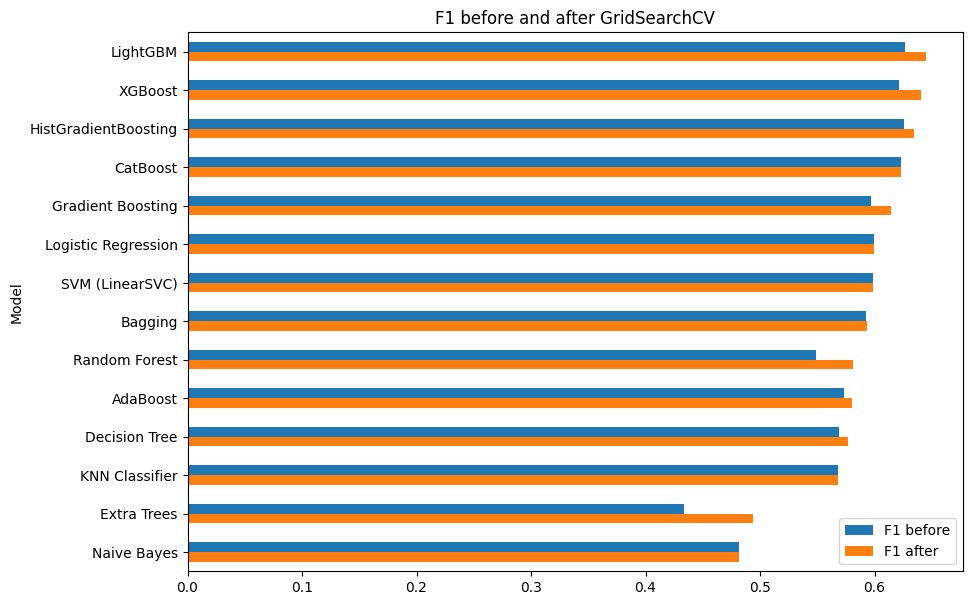

In [40]:
comparison.set_index('Model')[['F1 before', 'F1 after']].plot(kind='barh', figsize=(10, 7))
plt.title('F1 before and after GridSearchCV')
plt.gca().invert_yaxis()
plt.savefig('../results/before_after.png', bbox_inches='tight')
plt.show()

NameError: name 'y_test_proba' is not defined

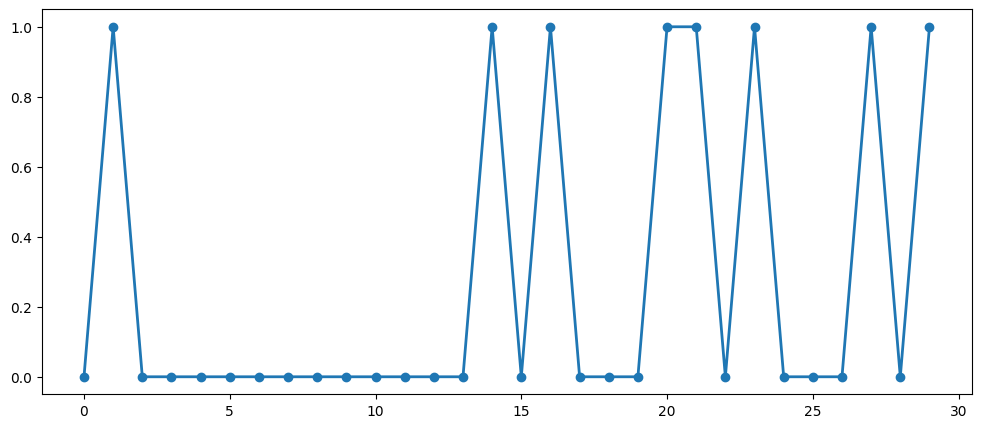

In [41]:
# 1. Actual vs Predicted Probability
plt.figure(figsize=(12, 5))
n_samples = 30
plt.plot(range(n_samples), y_test[:n_samples], marker='o', linestyle='-', label='Actual RainTomorrow (0 or 1)', linewidth=2)
plt.plot(range(n_samples), y_test_proba[:n_samples], marker='x', linestyle='--', label='Predicted Rain Probability', linewidth=2)
plt.axhline(y=best_thresh, color='red', linestyle=':', label=f'Threshold ({best_thresh:.2f})')

plt.title(f'Actual vs Predicted Probability (First {n_samples} Samples) - {best_name}')
plt.xlabel('Sample Index')
plt.ylabel('Probability / Class')
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig('../results/actual_vs_predicted_samples.png', bbox_inches='tight')
plt.show()

## **Test Results of All Models**

In [42]:
results = []
for name, pipe in best_models.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False)
results_df.to_csv('../results/test_results.csv', index=False)
print(results_df.to_string(index=False))

c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


               Model  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC
            LightGBM         0.8622     0.7556  0.5694    0.6494   0.8999
             XGBoost         0.8607     0.7616  0.5512    0.6395   0.8987
HistGradientBoosting         0.8590     0.7563  0.5476    0.6352   0.8940
            CatBoost         0.8576     0.7659  0.5255    0.6233   0.8888
   Gradient Boosting         0.8548     0.7572  0.5186    0.6156   0.8834
 Logistic Regression         0.8496     0.7359  0.5136    0.6050   0.8720
     SVM (LinearSVC)         0.8499     0.7391  0.5106    0.6040   0.8717
             Bagging         0.8510     0.7611  0.4888    0.5953   0.8737
            AdaBoost         0.8437     0.7194  0.4966    0.5876   0.8643
       Random Forest         0.8531     0.7961  0.4631    0.5855   0.8802
      KNN Classifier         0.8437     0.7247  0.4880    0.5832   0.8454
       Decision Tree         0.8417     0.7136  0.4905    0.5814   0.8556
         Extra Trees         0.8365   

## **final model**

In [43]:
best_name = comparison.loc[0, 'Model']
best_model = best_models[best_name]
print('Best model:', best_name)
print(comparison.loc[0, 'Best Params'])

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 4))
print('Average Precision:', round(average_precision_score(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred))

Best model: LightGBM
{'model__learning_rate': 0.1, 'model__n_estimators': 400, 'model__num_leaves': 63}
Accuracy: 0.8622
ROC-AUC: 0.8999
Average Precision: 0.7632

              precision    recall  f1-score   support

           0       0.88      0.95      0.91     22064
           1       0.76      0.57      0.65      6375

    accuracy                           0.86     28439
   macro avg       0.82      0.76      0.78     28439
weighted avg       0.86      0.86      0.85     28439



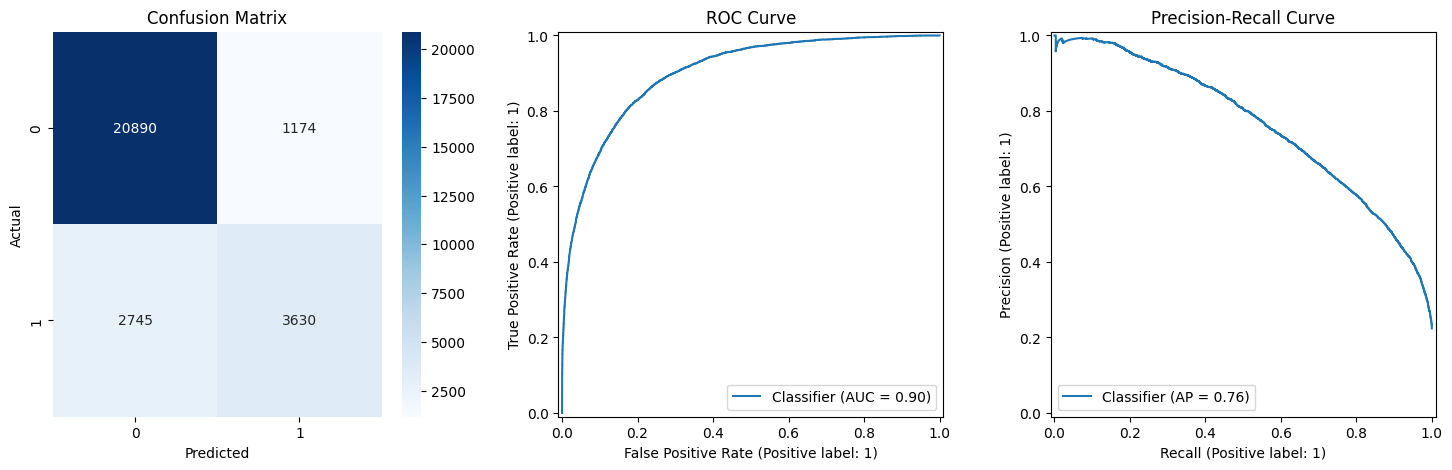

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.savefig('../results/final_model_evaluation.png', bbox_inches='tight')
plt.show()

## **save the model**

In [45]:
# Deployment
import joblib
joblib.dump(best_model, '../models/rain_prediction_pipeline.pkl')

loaded = joblib.load('../models/rain_prediction_pipeline.pkl')
print(loaded.predict(X_test.iloc[:5]))

[0 1 0 0 0]


With threshold 0.5, recall was low (0.57), so many rainy days were missed.
I picked the threshold on a validation split from the training data (not the test set).
The best value was 0.32. It raised recall to 0.72 and F1 to 0.68.

In [46]:
import joblib
import numpy as np
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Split training data into fitting and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a temporary model
validation_model = clone(best_model)
validation_model.fit(X_fit, y_fit)

# Select threshold using validation data only
y_val_proba = validation_model.predict_proba(X_val)[:, 1]

best_thresh = 0.5
best_f1 = 0

for thresh in np.arange(0.30, 0.70, 0.02):
    val_preds = (y_val_proba >= thresh).astype(int)
    score = f1_score(y_val, val_preds)

    if score > best_f1:
        best_f1 = score
        best_thresh = thresh

# Retrain final model using all training data
final_model = clone(best_model)
final_model.fit(X_train, y_train)

# Final evaluation on untouched test data
y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_pred_final = (y_test_proba >= best_thresh).astype(int)

print(f"Best Threshold: {best_thresh:.2f}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_final):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_final):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_test_proba):.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_final))

# Save final model and threshold
joblib.dump(
    {'pipeline': final_model, 'threshold': best_thresh},
    '../models/rain_prediction_pipeline.pkl'
)

print("Final model saved successfully!")

Best Threshold: 0.32
Test Accuracy: 0.8488
Precision: 0.6469
Recall: 0.7170
F1-Score: 0.6802
ROC-AUC: 0.8999

Classification Report:

              precision    recall  f1-score   support

           0       0.92      0.89      0.90     22064
           1       0.65      0.72      0.68      6375

    accuracy                           0.85     28439
   macro avg       0.78      0.80      0.79     28439
weighted avg       0.86      0.85      0.85     28439

Final model saved successfully!


In [51]:

import sklearn
import joblib
from pathlib import Path

print("Scikit-learn:", sklearn.__version__)

artifact = {
    "pipeline": final_model,
    "threshold": best_thresh
}

# Save model inside the project's model folder
model_path = Path('../models/rain_prediction_pipeline.pkl')

joblib.dump(artifact, model_path)

print("Model saved successfully!")
print("Saved at:", model_path.resolve())


Scikit-learn: 1.7.2
Model saved successfully!
Saved at: C:\Users\DELL\Downloads\Weather-Prediction-Project\model\rain_prediction_pipeline.pkl


In [47]:

import joblib
import pandas as pd

# Load the saved model and threshold
artifact = joblib.load('../models/rain_prediction_pipeline.pkl')

final_model = artifact['pipeline']
threshold = artifact['threshold']

print("Model loaded successfully!")
print("Threshold:", threshold)

# Display the input features
print("\nRequired input features:")
print(list(X_train.columns))

# Display one example input
print("\nExample weather data:")
print(X_test.iloc[0].to_dict())


Model loaded successfully!
Threshold: 0.32

Required input features:
['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'Month', 'Day']

Example weather data:
{'Location': 'Canberra', 'MinTemp': 15.1, 'MaxTemp': 32.9, 'Rainfall': 0.0, 'Evaporation': nan, 'Sunshine': nan, 'WindGustDir': 'E', 'WindGustSpeed': 50.0, 'WindDir9am': 'E', 'WindDir3pm': 'W', 'WindSpeed9am': 7.0, 'WindSpeed3pm': 11.0, 'Humidity9am': 73.0, 'Humidity3pm': 32.0, 'Pressure9am': 1015.5, 'Pressure3pm': 1011.8, 'Cloud9am': 7.0, 'Cloud3pm': nan, 'Temp9am': 19.0, 'Temp3pm': 30.3, 'RainToday': 'No', 'Month': 1, 'Day': 26}


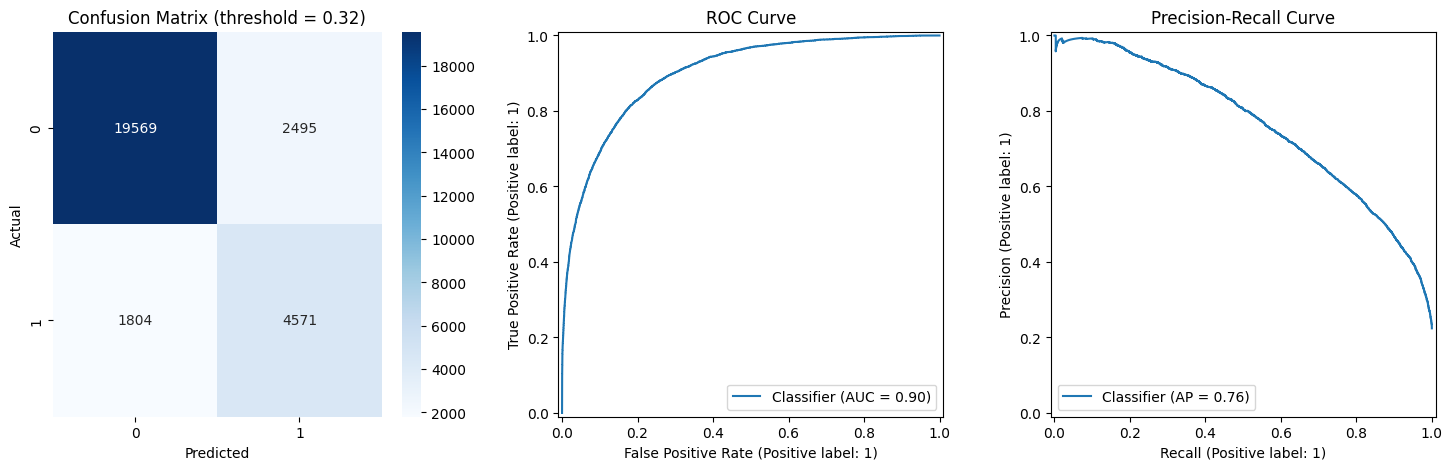

Average Precision: 0.7632


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Confusion Matrix (threshold = {best_thresh:.2f})')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
RocCurveDisplay.from_predictions(y_test, y_test_proba, ax=axes[1])
axes[1].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, y_test_proba, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')
plt.savefig('../results/final_model_evaluation.png', bbox_inches='tight')
plt.show()
print('Average Precision:', round(average_precision_score(y_test, y_test_proba), 4))

C:\Users\DELL\AppData\Local\Temp\ipykernel_8308\2466088626.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')


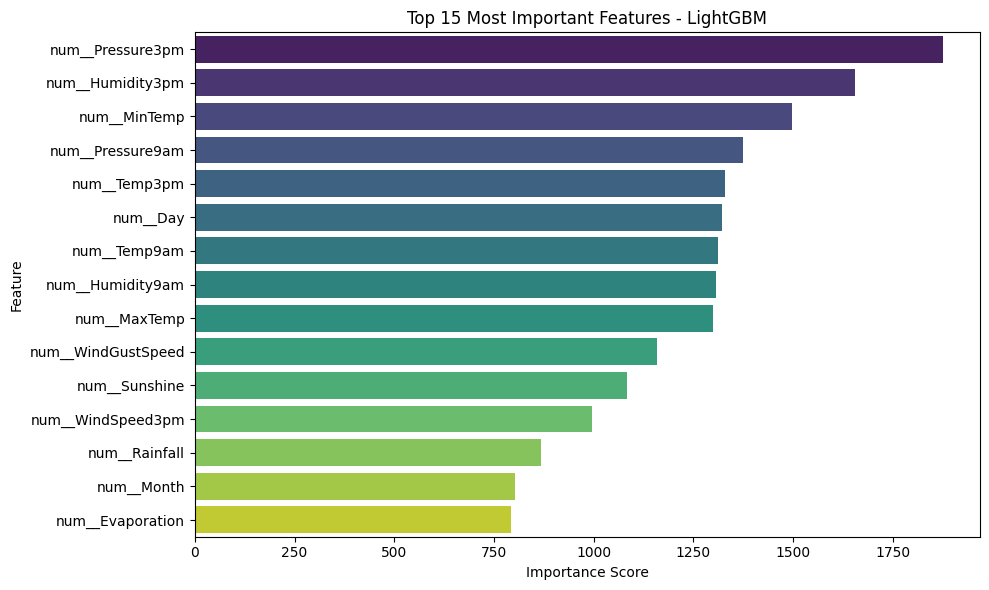

In [48]:
# Feature Importance
feature_names = best_model.named_steps['prep'].get_feature_names_out()
importances = best_model.named_steps['model'].feature_importances_

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis')
plt.title(f'Top 15 Most Important Features - {best_name}')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('../results/feature_importance.png', bbox_inches='tight')
plt.show()

##Final model: LightGBM with threshold 0.32.
Test results: F1 = 0.68, Recall = 0.72, Precision = 0.65, ROC-AUC = 0.90.
Top features: Humidity3pm, Sunshine, Pressure and Cloud3pm (see feature importance plot).
The model is better at predicting "No rain" than "Rain". Future work: add more features or try class weights.

In [ ]:
!pip install gradio

In [ ]:
import sklearn
import joblib
from google.colab import files

print("Scikit-learn:", sklearn.__version__)

artifact = {
    "pipeline": final_model,
    "threshold": best_thresh
}

joblib.dump(artifact, '../models/rain_prediction_pipeline.pkl')

files.download('../models/rain_prediction_pipeline.pkl')

In [49]:

import gradio as gr
import pandas as pd
import numpy as np
import joblib

# Load saved model
artifact = joblib.load('../models/rain_prediction_pipeline.pkl')
pipeline = artifact['pipeline']
threshold = artifact['threshold']

# Prediction function
def predict_rain(
    Location, MinTemp, MaxTemp, Rainfall, Evaporation, Sunshine,
    WindGustDir, WindGustSpeed, WindDir9am, WindDir3pm,
    WindSpeed9am, WindSpeed3pm, Humidity9am, Humidity3pm,
    Pressure9am, Pressure3pm, Cloud9am, Cloud3pm,
    Temp9am, Temp3pm, RainToday, Month, Day
):
    values = [[
        Location, MinTemp, MaxTemp, Rainfall, Evaporation, Sunshine,
        WindGustDir, WindGustSpeed, WindDir9am, WindDir3pm,
        WindSpeed9am, WindSpeed3pm, Humidity9am, Humidity3pm,
        Pressure9am, Pressure3pm, Cloud9am, Cloud3pm,
        Temp9am, Temp3pm, RainToday, Month, Day
    ]]

    columns = [
        'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
        'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am',
        'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
        'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am',
        'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'Month', 'Day'
    ]

    input_data = pd.DataFrame(values, columns=columns)

    # Predict probability
    probability = pipeline.predict_proba(input_data)[0][1]

    if probability >= threshold:
        result = "🌧️ Rain is expected tomorrow."
    else:
        result = "☀️ No rain is expected tomorrow."

    return (
        f"## {result}\n\n"
        f"Rain probability: **{probability:.2%}**\n\n"
        f"Decision threshold: **{threshold:.2f}**"
    )


# Create Gradio interface
inputs = [
    gr.Textbox(label="Location", value="Canberra"),
    gr.Number(label="Minimum Temperature (°C)", value=15.1),
    gr.Number(label="Maximum Temperature (°C)", value=32.9),
    gr.Number(label="Rainfall (mm)", value=0),
    gr.Number(label="Evaporation (mm)", value=None),
    gr.Number(label="Sunshine (hours)", value=None),
    gr.Textbox(label="Wind Gust Direction", value="E"),
    gr.Number(label="Wind Gust Speed (km/h)", value=50),
    gr.Textbox(label="Wind Direction at 9am", value="E"),
    gr.Textbox(label="Wind Direction at 3pm", value="W"),
    gr.Number(label="Wind Speed at 9am (km/h)", value=7),
    gr.Number(label="Wind Speed at 3pm (km/h)", value=11),
    gr.Number(label="Humidity at 9am (%)", value=73),
    gr.Number(label="Humidity at 3pm (%)", value=32),
    gr.Number(label="Pressure at 9am (hPa)", value=1015.5),
    gr.Number(label="Pressure at 3pm (hPa)", value=1011.8),
    gr.Number(label="Cloud at 9am (oktas)", value=7),
    gr.Number(label="Cloud at 3pm (oktas)", value=None),
    gr.Number(label="Temperature at 9am (°C)", value=19),
    gr.Number(label="Temperature at 3pm (°C)", value=30.3),
    gr.Textbox(label="Rain Today (Yes/No)", value="No"),
    gr.Number(label="Month", value=1),
    gr.Number(label="Day", value=26)
]

demo = gr.Interface(
    fn=predict_rain,
    inputs=inputs,
    outputs=gr.Markdown(),
    title="Rain Tomorrow Prediction",
    description="Enter today's weather conditions to predict whether it will rain tomorrow."
)

demo.launch(share=True)


c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


In [50]:
import sklearn
import lightgbm
import joblib

print("Scikit-learn:", sklearn.__version__)
print("LightGBM:", lightgbm.__version__)
print("Joblib:", joblib.__version__)

Scikit-learn: 1.7.2
LightGBM: 4.7.0
Joblib: 1.5.3
